<div dir="rtl">

### פרטי הסטודנטים
* **שם:** מתן
* **אות ראשונה של שם המשפחה:** א
* **4 ספרות אחרונות של ת"ז:** 5965
* **שם:** אופיר
* **אות ראשונה של שם המשפחה:** א
* **4 ספרות אחרונות של ת"ז:** 9461
</div>

<div dir="rtl">

### פרומפטים ב-AI LLM ועזרים נוספים
* **כלי ה-AI:** Gemini
* **פרומפטים:** "אני משתמש ב-fashion mnist מ-kaggle", "איך לסדר כתיבה בעברית במחברת", "מה לרשום על בעיית הלימוד".
* **מטרה:** סיוע בבניית שלד המחברת לפי דרישות המטלה, פתרון תקלות טכניות ב-Kernel וב-uv, וארגון המידע להגשה.

*עזרה בתכנון מבנה התפרויקט 
</div>

<div dir="rtl">

### הסבר על ה-Dataset ובעיית הלמידה
במטלה זו אנו מתמודדים עם בעיית **סיווג (Classification)** בתחום הראייה הממוחשבת. בחרנו להשתמש ב-**MNIST Dataset** מ-Kaggle.  הבעיה היא מסוג **למידה מונחית (Supervised Learning)**, כאשר המטרה היא לאמן מודל שיזהה 10 קטגוריות שונות של מוצרי אופנה (חולצות, מכנסיים, נעליים וכו׳) מתוך תמונות פיקסלים.  

</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
train = pd.read_csv('fashion mnist/fashion-mnist_train.csv')
test = pd.read_csv('fashion mnist/fashion-mnist_test.csv')
print("First 5 rows of test set:\n")
display(test.head())
print("\nFirst 5 rows of train set:\n")
display(train.head())


First 5 rows of test set:



,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



First 5 rows of train set:



,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


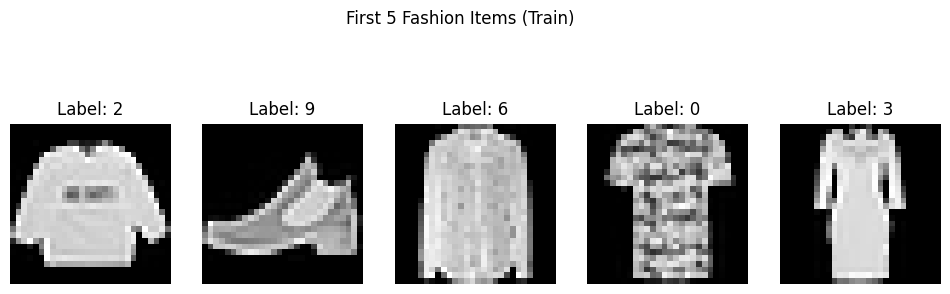

In [4]:
def show_first_five(df, title):
    plt.figure(figsize=(12, 4))
    for i in range(5):
        pixels = df.iloc[i, 1:].values.reshape(28, 28)
        label = df.iloc[i, 0]
        
        plt.subplot(1, 5, i + 1)
        plt.imshow(pixels, cmap='gray')
        plt.title(f"Label: {label}")
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

show_first_five(train, "First 5 Fashion Items (Train)")

In [5]:
def calculate_macro_f1(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    classes = np.unique(y_true)
    f1_scores = []

    for c in classes:
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0

        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        f1_scores.append(f1)

    macro_f1 = sum(f1_scores) / len(f1_scores)
    print(f"Manual Macro-Average F1 Score: {macro_f1:.4f}")
    return float(macro_f1)

# הרצה לבדיקה עם נתוני דמה
y_test_demo = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
y_pred_demo = [0, 1, 2, 0, 4, 5, 9, 7, 8, 9] 
calculate_macro_f1(y_test_demo, y_pred_demo)

Manual Macro-Average F1 Score: 0.7333


0.7333333333333333

## Part 2 - Feature Engineering
### 1. Normalization

In [6]:
# הפרדת התוויות מהנתונים
y_train = train.iloc[:, 0].values
y_test = test.iloc[:, 0].values

# נורמליזציה של הפיקסלים לטווח 0-1 על ידי חלוקה ב-255.0
X_train = train.iloc[:, 1:].values / 255.0
X_test = test.iloc[:, 1:].values / 255.0

# הצגת 3 דוגמאות
print("Part 2: Feature engineering verification")
for i in range(3):
    original = train.iloc[i, 401] # הערך המקורי מהקובץ
    normalized = X_train[i, 400]  # הערך המנורמל במערך החדש
    print(f"Example {i+1}: original pixel: {original} - normalized: {normalized:.4f}")

Part 2: Feature engineering verification
Example 1: original pixel: 221 - normalized: 0.8667
Example 2: original pixel: 0 - normalized: 0.0000
Example 3: original pixel: 205 - normalized: 0.8039


<div dir="rtl">

### 2. One-Hot Encoding
המרת התוויות (Labels) לווקטורים בינאריים עבור 10 המחלקות של ה-Dataset. פעולה זו הכרחית עבור רשת הניירונים (ANN) שנממש בהמשך כדי שתוכל להשוות בין פלט המודל לתווית האמיתית.
</div>

In [7]:
def to_one_hot(labels, num_classes=10):
    # יצירת מטריצת אפסים בגודל הנתונים
    one_hot = np.zeros((labels.size, num_classes))
    one_hot[np.arange(labels.size), labels] = 1
    return one_hot

# המרת תוויות האימון והבדיקה
y_train_onehot = to_one_hot(y_train)
y_test_onehot = to_one_hot(y_test)

# בדיקת התוצאה עבור 3 דוגמאות
print("One-Hot Encoding Verification")
for i in range(3):
    print(f"Example {i+1}: original label: {y_train[i]} - vector: {y_train_onehot[i]}")

One-Hot Encoding Verification
Example 1: original label: 2 - vector: [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
Example 2: original label: 9 - vector: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Example 3: original label: 6 - vector: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## Part 3 - Learning Algorithm Implementation
### Artificial Neural Network (ANN)

<div dir="rtl">

</div>

In [8]:
# פונקציות אקטיבציה
def relu(Z):
    return np.maximum(0, Z)

def softmax(Z):
    expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return expZ / np.sum(expZ, axis=1, keepdims=True)

# אתחול פרמטרים של הרשת
def initialize_params(input_size, hidden_size, output_size):
    params = {
        "W1": np.random.randn(input_size, hidden_size) * 0.01,
        "b1": np.zeros((1, hidden_size)),
        "W2": np.random.randn(hidden_size, output_size) * 0.01,
        "b2": np.zeros((1, output_size))
    }
    return params

# מעבר קדימה ברשת
def forward(X, params):
    Z1 = np.dot(X, params['W1']) + params['b1']
    A1 = relu(Z1)
    Z2 = np.dot(A1, params['W2']) + params['b2']
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

# חישוב נגזרות 
def backward(X, Y, Z1, A1, A2, params):
    m = X.shape[0]
    
    # חישוב שגיאה בשכבת הפלט
    dZ2 = A2 - Y
    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m
    
    # חישוב שגיאה בשכבה הנסתרת
    dA1 = np.dot(dZ2, params['W2'].T)
    dZ1 = dA1 * (Z1 > 0)
    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m
    
    return dW1, db1, dW2, db2

#פונקציית אימון עם hyperparameters
def train_model(X, Y, hidden_size=64, epochs=100, lr=0.1):
    input_size = X.shape[1]
    output_size = Y.shape[1]
    params = initialize_params(input_size, hidden_size, output_size)
    
    print("Training Started")
    for i in range(epochs):
        # הרצת שלבי הלמידה
        Z1, A1, Z2, A2 = forward(X, params)
        dW1, db1, dW2, db2 = backward(X, Y, Z1, A1, A2, params)
        
        # עדכון הפרמטרים (Gradient Descent)
        params['W1'] -= lr * dW1
        params['b1'] -= lr * db1
        params['W2'] -= lr * dW2
        params['b2'] -= lr * db2
        
        # הדפסת שגיאה כל 10 איטרציות
        if i % 10 == 0:
            loss = -np.mean(Y * np.log(A2 + 1e-8))
            print(f"Epoch {i}: Loss = {loss:.4f}")
            
    return params

# פונקציית חיזוי
def predict(X, params):
    _, _, _, A2 = forward(X, params)
    return np.argmax(A2, axis=1)

trained_params = train_model(X_train, y_train_onehot, hidden_size=64, epochs=100, lr=0.1)

Training Started
Epoch 0: Loss = 0.2302
Epoch 10: Loss = 0.2277
Epoch 20: Loss = 0.2187
Epoch 30: Loss = 0.1959
Epoch 40: Loss = 0.1647
Epoch 50: Loss = 0.1413
Epoch 60: Loss = 0.1253
Epoch 70: Loss = 0.1136
Epoch 80: Loss = 0.1050
Epoch 90: Loss = 0.0984


## Part 4 - Training the Model
<div dir="rtl">
הפעלת פונקציית האימון על הנתונים המנורמלים.
</div>

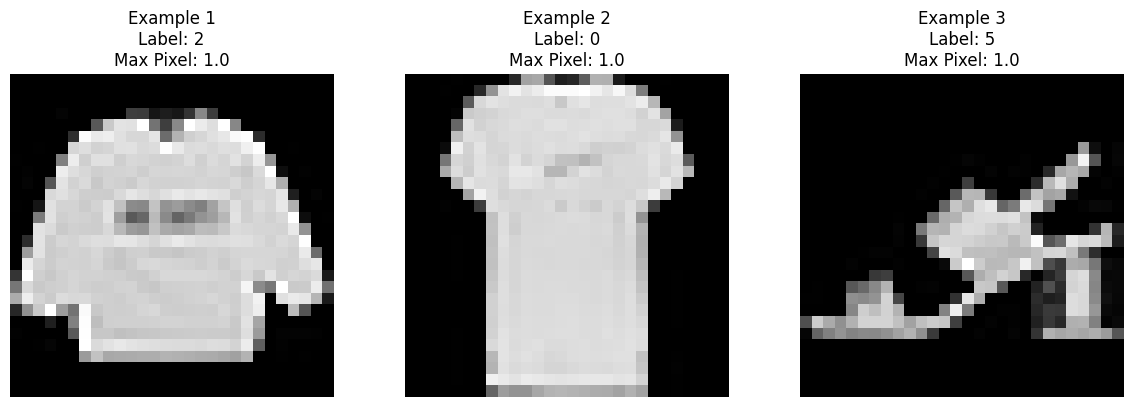

Calculation: Normalizing Pixel 400: 221 / 255 = 0.8667


In [9]:
indices = [0, 10, 50]

plt.figure(figsize=(12, 4))

for i, idx in enumerate(indices):
    raw_pixel_sample = train.iloc[idx, 1:785].values.reshape(28, 28)

    processed_sample = X_train[idx].reshape(28, 28)

    plt.subplot(1, 3, i+1)
    plt.imshow(processed_sample, cmap='gray')
    plt.title(f"Example {i+1}\nLabel: {y_train[idx]}\nMax Pixel: {processed_sample.max()}")
    plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Calculation: Normalizing Pixel 400: {train.iloc[indices[0], 401]} / 255 = {X_train[indices[0], 400]:.4f}")

## Part 5 - Results and Evaluation
<div dir="rtl">
חיזוי על ה-Test Set, הצגת 5 הדגימות הראשונות וחישוב Macro-Average F1.
</div>

Overall Accuracy: 65.74%
Manual Macro-Average F1 Score: 0.6134
Macro-Average F1 Score: 0.6134


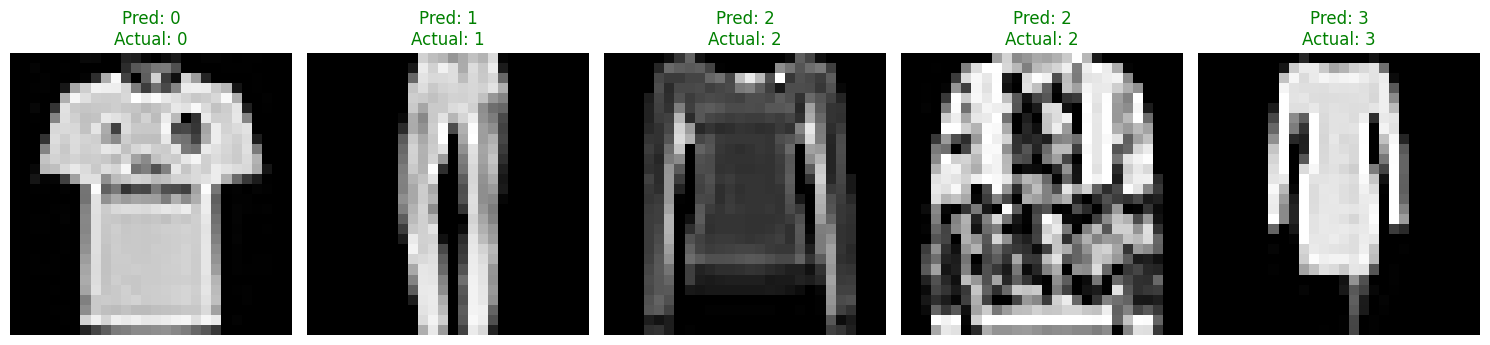

In [10]:
# חיזוי וחישוב אחוזי הצלחה
y_pred = predict(X_test, trained_params)
accuracy = np.mean(y_pred == y_test) * 100

print(f"Overall Accuracy: {accuracy:.2f}%")
print(f"Macro-Average F1 Score: {calculate_macro_f1(y_test, y_pred):.4f}")

# הצגת 5 חיזויים ראשונים עם תמונות
plt.figure(figsize=(15, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    
    # צבע ירוק להצלחה, אדום לטעות
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    
    plt.title(f"Pred: {y_pred[i]}\nActual: {y_test[i]}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#Grid search with k-fold cross validation (אתחולים של הפרמטרים)
learning_rates = [0.1, 0.05]
hidden_sizes = [32, 64]
k = 5
fold_size = len(X_train) // k
results = []

print(f"Starting Grid Search with {k}-fold Cross Validation")

for lr in learning_rates:
    for hs in hidden_sizes:
        fold_scores = []
        print(f"Testing: lr={lr}, hidden_size={hs}")
        
        for i in range(k):
            # חלוקה ל-Folds
            start, end = i * fold_size, (i + 1) * fold_size
            X_val_fold = X_train[start:end]
            y_val_fold = y_train[start:end] # הלייבלים המקוריים לחישוב F1
            
            X_train_fold = np.concatenate([X_train[:start], X_train[end:]])
            y_train_fold_onehot = np.concatenate([y_train_onehot[:start], y_train_onehot[end:]])
            
            # אימון על ה-Fold הנוכחי
            params = train_model(X_train_fold, y_train_fold_onehot, hidden_size=hs, epochs=50, lr=lr)
            
            # חיזוי והערכה
            preds = predict(X_val_fold, params)
            score = calculate_macro_f1(y_val_fold, preds)
            fold_scores.append(score)
            
        avg_f1 = np.mean(fold_scores)
        results.append({
            'Learning Rate': lr,
            'Hidden Size': hs,
            'Avg Macro F1': avg_f1
        })

# הצגת הניסויים ב-DataFrame 
results_df = pd.DataFrame(results)
display(results_df)

# בחירת הפרמטרים הטובים ביותר
best_result = results_df.loc[results_df['Avg Macro F1'].idxmax()]
print(f"\nBest Permutation: lr={best_result['Learning Rate']}, hs={int(best_result['Hidden Size'])}")

--- Starting Grid Search with 5-fold Cross Validation ---
Testing: lr=0.1, hidden_size=32...
Training Started
Epoch 0: Loss = 0.2302
Epoch 10: Loss = 0.2292
Epoch 20: Loss = 0.2249
Epoch 30: Loss = 0.2105
Epoch 40: Loss = 0.1811
Manual Macro-Average F1 Score: 0.4030
Training Started
Epoch 0: Loss = 0.2303
Epoch 10: Loss = 0.2294
Epoch 20: Loss = 0.2260
Epoch 30: Loss = 0.2133
Epoch 40: Loss = 0.1874
Manual Macro-Average F1 Score: 0.3929
Training Started
Epoch 0: Loss = 0.2302
Epoch 10: Loss = 0.2289
Epoch 20: Loss = 0.2226
Epoch 30: Loss = 0.2049
Epoch 40: Loss = 0.1767
Manual Macro-Average F1 Score: 0.4418
Training Started
Epoch 0: Loss = 0.2303
Epoch 10: Loss = 0.2292
Epoch 20: Loss = 0.2246
Epoch 30: Loss = 0.2086
Epoch 40: Loss = 0.1810
Manual Macro-Average F1 Score: 0.3633
Training Started
Epoch 0: Loss = 0.2302
Epoch 10: Loss = 0.2291
Epoch 20: Loss = 0.2247
Epoch 30: Loss = 0.2110
Epoch 40: Loss = 0.1844
Manual Macro-Average F1 Score: 0.4431
Testing: lr=0.1, hidden_size=64...
Tr

,Learning Rate,Hidden Size,Avg Macro F1
0,0.10,32,0.408834
1,0.10,64,0.482096
2,0.05,32,0.098258
3,0.05,64,0.168206



Best Permutation: lr=0.1, hs=64


In [ ]:
# כעת מאמנים את המודל על כל ה-Train Set עם הפרמטרים המנצחים
final_lr = best_result['Learning Rate']
final_hs = int(best_result['Hidden Size'])

print(f"Training Final Model (lr={final_lr}, hs={final_hs})")
final_params = train_model(X_train, y_train_onehot, hidden_size=final_hs, epochs=100, lr=final_lr)

# חיזוי סופי על ה-Test Set
final_preds = predict(X_test, final_params)
final_accuracy = np.mean(final_preds == y_test) * 100
final_f1 = calculate_macro_f1(y_test, final_preds)

print(f"\nFinal Test Results:")
print(f"Accuracy: {final_accuracy:.2f}%")
print(f"Macro F1: {final_f1:.4f}")

--- Training Final Model (lr=0.1, hs=64) ---
Training Started
Epoch 0: Loss = 0.2303
Epoch 10: Loss = 0.2286
Epoch 20: Loss = 0.2218
Epoch 30: Loss = 0.2022
Epoch 40: Loss = 0.1728
Epoch 50: Loss = 0.1490
Epoch 60: Loss = 0.1320
Epoch 70: Loss = 0.1191
Epoch 80: Loss = 0.1090
Epoch 90: Loss = 0.1012
Manual Macro-Average F1 Score: 0.6017

Final Test Results:
Accuracy: 64.97%
Macro F1: 0.6017
